# Circuit expansion for learning in neural networks

A guided walkthrough of

> J. Steinberg, M. Advani & H. Sompolinsky, *New role for circuit expansion for learning in neural networks*, **Phys. Rev. E 103, 022404 (2021)** (Editors' Suggestion).

A perceptron *student* learns a noisy *teacher* rule. Label noise makes the rule **unrealizable**: beyond a critical training-set size — the **capacity** — the examples cannot all be fit, and max-margin learning stalls. Widening the student with a random input expansion raises the capacity, lets it train on more examples, and — the central result — *improves* generalization, most of all when the expanded units are **sparse** and are **pruned** after learning. This notebook builds the picture from the teacher-student geometry up through the replica mean-field theory, validating each step against simulation with the `nn_expansion` package.

*Drafted with the assistance of Claude (Anthropic).*

In [1]:
# needs the package installed: pip install -e .   (from the repo root)
import numpy as np
import matplotlib.pyplot as plt
from nn_expansion import theory as T
from nn_expansion.teacher import min_generalization_error, quad_to_noise_sigma
from nn_expansion.simulate import TrialSpec, MaxMargin, Logistic, NoExpansion, Stochastic, Deterministic
from nn_expansion.sweep import run_series

plt.rcParams.update({"figure.figsize": (6.4, 4.3), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11, "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False})
ACCENT, TEACH, GREEN, GREY = "#1f5fa8", "#c0392b", "#27ae60", "#888888"


def curve(a0s, field, trials, seed, series, **spec):
    """Mean of `field` over separable trials at each alpha0, for TrialSpec(**spec)."""
    specs = [TrialSpec(alpha0=float(a), **spec) for a in a0s]
    sw, _ = run_series(specs, trials, seed, series, n_jobs=-1)
    return sw.mean(field, "separable_only")

## 1. The teacher, the student, and the geometry of generalization

The teacher is a perceptron with weights $\mathbf w^0$. Each input $\mathbf x\in\mathbb R^{N_0}$, $x_i\sim\mathcal N(0,1)$, gets the label $y^0=\operatorname{sgn}(h^0)$ from the noisy field (Eq. 1)

$$ h^0 = \frac{1}{\sqrt{N_0}}\,\mathbf w^0\!\cdot\!\mathbf x + \epsilon,\qquad \epsilon\sim\mathcal N(0,\sigma_{\rm out}^2). $$

The signal $\tfrac1{\sqrt{N_0}}\mathbf w^0\!\cdot\!\mathbf x$ is unit variance, so $\sigma_{\rm out}$ is the label noise relative to the signal. The student outputs $y=\operatorname{sgn}(\tfrac1{\sqrt N}\mathbf w\!\cdot\!\mathbf x)$, and its generalization error (Eq. 2) is the probability that the two hyperplanes disagree,

$$ E_g = \big\langle \Theta(-y^0 y)\big\rangle_{\mathbf x,\epsilon}. $$

For Gaussian inputs this depends only on the **angle** between the weight vectors. With $R=\cos\theta$ the cosine of the student-teacher angle, integrating the joint Gaussian of the two fields gives the closed form (Eq. 23)

$$ E_g(R) = \frac1\pi\Big(\frac\pi2-\arctan\frac{R}{\sqrt{1+\sigma_{\rm out}^2-R^2}}\Big). $$

A perfectly aligned student ($R=1$) cannot do better than the noise floor (Eq. 4),

$$ E_{\min} = E_g(1) = \frac1\pi\Big(\frac\pi2-\arctan\frac{1}{\sigma_{\rm out}}\Big), $$

the irreducible error from the teacher's own label noise.

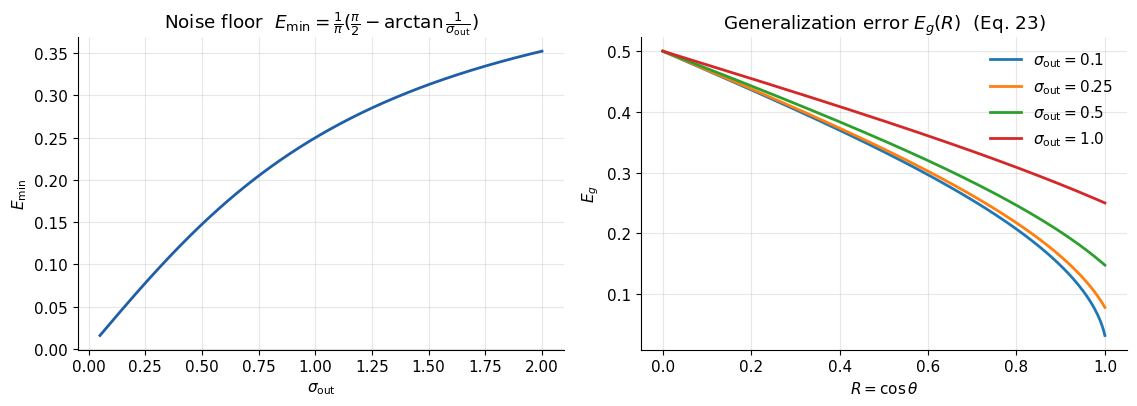

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))

so = np.linspace(0.05, 2.0, 300)
ax[0].plot(so, min_generalization_error(so), color=ACCENT)
ax[0].set(xlabel=r"$\sigma_{\rm out}$", ylabel=r"$E_{\min}$",
          title=r"Noise floor  $E_{\min}=\frac{1}{\pi}(\frac{\pi}{2}-\arctan\frac{1}{\sigma_{\rm out}})$")

R = np.linspace(0, 1, 300)
for s in (0.1, 0.25, 0.5, 1.0):
    ax[1].plot(R, T.eg_from_overlap(R, s), label=fr"$\sigma_{{\rm out}}={s}$")
ax[1].set(xlabel=r"$R=\cos\theta$", ylabel=r"$E_g$",
          title=r"Generalization error $E_g(R)$  (Eq. 23)")
ax[1].legend(frameon=False)
plt.tight_layout()

## 2. Capacity of the unrealizable rule

Label noise breaks linear separability beyond a critical number of examples. Define the measurement density $\alpha_0=P/N_0$. The **capacity** $\alpha_c$ is the largest $\alpha_0$ for which a perceptron can still fit every training label; above it, max-margin has no solution. Setting the margin $\kappa\to0$ in the mean-field equations gives the capacity equations (Eqs. C4-C5, with $\bar m=m/\sqrt{1+\sigma_{\rm out}^2}$, $\alpha=\alpha_0/\beta$)

$$ 1-m^2=\frac\alpha\pi\Big[\operatorname{arccot}\frac{\bar m}{\sqrt{1-\bar m^2}}-\bar m\sqrt{1-\bar m^2}\Big],\qquad \frac{\bar m}{\sqrt{1-\bar m^2}}=\frac{\alpha}{\pi(1+\sigma_{\rm out}^2)}. $$

At $\sigma_{\rm in}=1$ these involve $\alpha=\alpha_0/\beta$ but not $\beta$ alone, so the capacity in $\alpha_0$ scales **linearly** with the expansion (Eq. C6):

$$ \boxed{\ \alpha_c(\beta,\sigma_{\rm out}) = \beta\,\alpha_c(1,\sigma_{\rm out})\ } $$

As $\sigma_{\rm out}\to\infty$ the labels become random and $\alpha_c\to2$, the Gardner bound for storing random dichotomies.

alpha_c(1, 0.25) = 7.523
alpha_c(5, 0.25)/alpha_c(1, 0.25) = 5.000  (== beta = 5)
alpha_c(1, 50)   = 2.000  (Gardner -> 2)


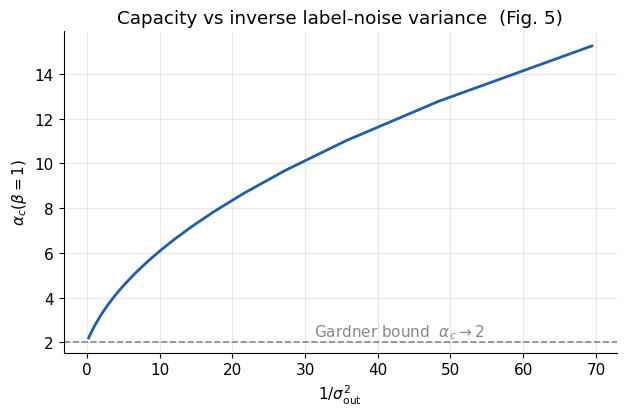

In [3]:
so = np.linspace(0.12, 2.0, 80)
ac = np.array([T.capacity_alpha0(1.0, s) for s in so])

fig, ax = plt.subplots()
ax.plot(1.0 / so**2, ac, color=ACCENT)
ax.axhline(2.0, ls="--", color=GREY, lw=1.2)
ax.text(np.max(1/so**2)*0.45, 2.25, r"Gardner bound  $\alpha_c\to 2$", color=GREY)
ax.set(xlabel=r"$1/\sigma_{\rm out}^2$", ylabel=r"$\alpha_c(\beta{=}1)$",
       title=r"Capacity vs inverse label-noise variance  (Fig. 5)")
plt.tight_layout()

print(f"alpha_c(1, 0.25) = {T.capacity_alpha0(1, 0.25):.3f}")
print(f"alpha_c(5, 0.25)/alpha_c(1, 0.25) = {T.capacity_alpha0(5, 0.25)/T.capacity_alpha0(1, 0.25):.3f}  (== beta = 5)")
print(f"alpha_c(1, 50)   = {T.capacity_alpha0(1, 50):.3f}  (Gardner -> 2)")

## 3. The central result: expand to learn, then prune

We widen the student to $N=\beta N_0$ by appending $N_+=(\beta-1)N_0$ units. Two schemes:

* **deterministic** (Eqs. 5-6): a fixed random map $J$ feeds threshold units with firing sparsity $f$ and activity scale $A$,
  $\;z_j=\tfrac{A}{\sqrt{f(1-f)}}\big(\Theta((Jx)_j-T)-f\big)$;
* **stochastic** (Eq. 10): units drawn fresh per pattern, $\tilde x_j\sim\mathcal N(0,\sigma_{\rm in}^2)$ — the analytically tractable surrogate of a very sparse deterministic layer.

Either way the student field is $h=\tfrac1{\sqrt N}(\mathbf w\!\cdot\!\mathbf x+\tilde{\mathbf w}\!\cdot\!\mathbf u)$, trained to the max-margin solution (Eqs. 8-9). After training we test two ways: **pruned** (drop the expanded weights, keep only the $N_0$ teacher-subspace block) or **unpruned** (retain them). The simulation below reproduces the key finding: a **sparse** expansion generalizes best and best of all once pruned, while a **dense** expansion is best left unpruned but never beats sparse+pruned.

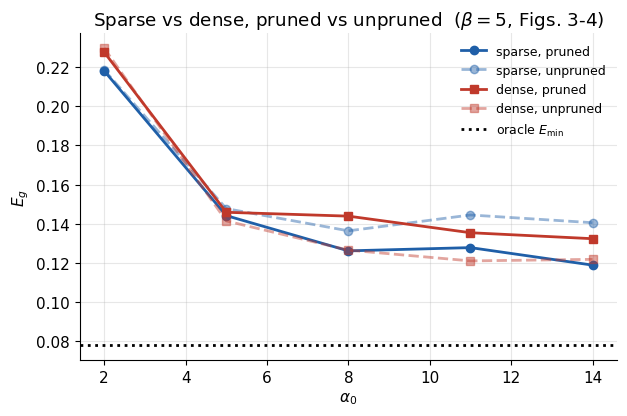

In [4]:
N0, beta, so, A = 70, 5.0, 0.25, 0.2
a0s = np.array([2., 5., 8., 11., 14.])

def det_curves(f, series):
    spec = dict(N0=N0, teacher_a=1.0, sigma_out=so, expansion=Deterministic(beta, f, A),
                learner=MaxMargin(), student="linear", measure_unpruned=True, n_test=4000)
    return (curve(a0s, "eg_pruned", 5, 0, series, **spec),
            curve(a0s, "eg_unpruned", 5, 0, series, **spec))

sp_pr, sp_un = det_curves(0.02, 0)   # sparse
de_pr, de_un = det_curves(0.50, 1)   # dense

fig, ax = plt.subplots()
ax.plot(a0s, sp_pr, "o-",  color=ACCENT, label="sparse, pruned")
ax.plot(a0s, sp_un, "o--", color=ACCENT, alpha=0.45, label="sparse, unpruned")
ax.plot(a0s, de_pr, "s-",  color=TEACH,  label="dense, pruned")
ax.plot(a0s, de_un, "s--", color=TEACH,  alpha=0.45, label="dense, unpruned")
ax.axhline(min_generalization_error(so), ls=":", color="k", label=r"oracle $E_{\min}$")
ax.set(xlabel=r"$\alpha_0$", ylabel=r"$E_g$",
       title=fr"Sparse vs dense, pruned vs unpruned  ($\beta={beta:g}$, Figs. 3-4)")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()

## 4. Replica mean-field theory

We compute the *typical* generalization error by averaging the log-volume of the version space over training sets with the replica trick. For $n$ replicated students obeying the max-margin constraints (Eq. 11),

$$ \langle V^n\rangle = \Big\langle \prod_a\!\int\! d\mathbf w^a\, d\tilde{\mathbf w}^a\,\delta\!\big(\|\mathbf w^a\|^2+\|\tilde{\mathbf w}^a\|^2-N\big)\prod_{\mu}\Theta\!\big(\sigma h^{\mu a}-\kappa\big)\Big\rangle. $$

Introduce the order parameters (Eqs. 12-15): the student-teacher overlap $m^a=\tfrac1N\mathbf w^0\!\cdot\!\mathbf w^a$, the expanded-norm $\tilde r^a=\tfrac1N\|\tilde{\mathbf w}^a\|^2$, and the replica overlaps $q^{ab},\tilde q^{ab}$. The version space is convex and connected, so the **replica-symmetric** ansatz is exact and the free energy splits into entropic and energetic pieces,

$$ \tfrac1N\log\langle V\rangle = G_0(\tilde r,m)+\alpha\,G_1(\tilde r,m),\qquad \alpha=\alpha_0/\beta. $$

In the max-margin limit $q\to1-\tilde r,\ \tilde q\to\sigma_{\rm in}^2\tilde r$. Specializing to $\sigma_{\rm in}=1$, the saddle reduces to **two coupled equations** for $(m,\kappa)$ — the volume-vanishing condition and the $m$-saddle (`theory._err1`, `theory._err2`; with $\bar m=m/\sqrt{1+\sigma_{\rm out}^2}$, $H(z)=\int_z^\infty\!Dy$, $k_*=\kappa/\sqrt{1-\bar m^2}$):

$$ 1-m^2 = 2\alpha\!\int_{-\infty}^{\kappa}\! Dx\;H\!\Big(\!-\tfrac{\bar m}{\sqrt{1-\bar m^2}}\,x\Big)(\kappa-x)^2, $$

$$ \frac{\bar m}{\sqrt{1-\bar m^2}} = \frac{\alpha}{\sqrt{2\pi}\,(1+\sigma_{\rm out}^2)}\int_{-k_*}^{\infty}\! Dx\;(k_*+x)^2\,x. $$

The expansion enters generalization **only** through the pruned overlap (Eq. B18)

$$ R = \frac{m\sqrt\beta}{\sqrt{1+(\beta-1)m^2}},\qquad E_g=\tfrac12-\tfrac1\pi\arctan\frac{R}{\sqrt{1-R^2+\sigma_{\rm out}^2}}. $$

**Geometric reading.** $\sqrt{1-\tilde r}$ is the fraction of the student's weight norm lying in the teacher's subspace; $R=m/\sqrt{1-\tilde r}$ is the cosine of the angle *after projecting out* the expansion. Since the expanded activity is uncorrelated with the task, retaining it merely injects noise into the test field, so $R\ge m$ and **pruning always helps** in the stochastic model. The $\beta\to\infty$ envelope (Eq. E8 / `large_beta_R2`) is $R^2=X/(1+X)$ with $X=(2\alpha_0/\pi)/(1+\sigma_{\rm out}^2)$.

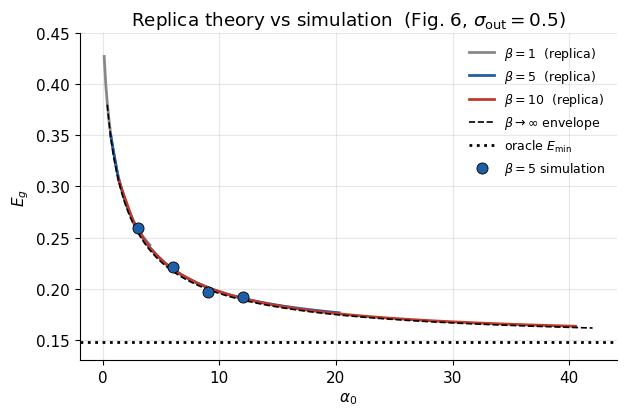

In [5]:
so = 0.5
fig, ax = plt.subplots()

# replica Eg(alpha0) for several beta, each up to its capacity
for beta, col in [(1.0, GREY), (5.0, ACCENT), (10.0, TEACH)]:
    a0max = T.capacity_alpha0(beta, so) * 0.98
    a0 = np.linspace(a0max / 30, a0max, 30)
    ax.plot(a0, T.eg_curve_sigma_in_1(a0, beta, so, pruned=True), color=col,
            label=fr"$\beta={beta:g}$  (replica)")

# beta -> infinity envelope and oracle
a0e = np.linspace(0.4, 42, 250)
ax.plot(a0e, T.large_beta_eg(a0e, so), "k--", lw=1.2, label=r"$\beta\to\infty$ envelope")
ax.axhline(min_generalization_error(so), ls=":", color="k", label=r"oracle $E_{\min}$")

# overlay a max-margin simulation at beta=5 (stochastic, sigma_in=1)
a0s = np.array([3., 6., 9., 12.])
sim = curve(a0s, "eg_pruned", 6, 0, 2, N0=60, teacher_a=1.0, sigma_out=so,
            expansion=Stochastic(5.0, 1.0), learner=MaxMargin(), student="linear",
            measure_unpruned=False, n_test=0)
ax.plot(a0s, sim, "o", color=ACCENT, ms=8, mec="k", mew=0.6, label=r"$\beta=5$ simulation")

ax.set(xlabel=r"$\alpha_0$", ylabel=r"$E_g$", ylim=(0.13, 0.45),
       title=r"Replica theory vs simulation  (Fig. 6, $\sigma_{\rm out}=0.5$)")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()

## 5. Stochastic vs deterministic, and the slack-regularization picture

With $\sigma_{\rm in}=A=1$ the stochastic and deterministic models have matched expansion statistics. The stochastic network is best; the deterministic **sparse** network approaches it as $f\to0$ (weak correlations), while the **dense** network lags. The replica curve overlays the stochastic simulation.

**Why does widening help at all?** Widening raises capacity but also Rademacher complexity, so the benefit is not automatic. The resolution (Sec. III B): the expanded SVM in the realizable regime equals the *unexpanded* SVM in the unrealizable regime with **slack regularization**. The minimal expanded weights live in the span of the stochastic vectors, $\tilde{\mathbf w}=(\tilde X^\top)^+\boldsymbol\xi$, and substituting turns the objective into a Mahalanobis-penalized slack SVM (Eqs. 28-29) with $C_{\mu\nu}=\tilde{\mathbf x}_\mu\!\cdot\!\tilde{\mathbf x}_\nu$. For large $\beta$ the units decorrelate, $C\to\sigma_{\rm in}^2 I$, and this becomes the generic L2 slack with trade-off $C=\sigma_{\rm in}^{-2}$ (Eq. 30).

1 - cos(w_expanded, w_slack): [0.1015 0.0783 0.0523 0.0208 0.0062]


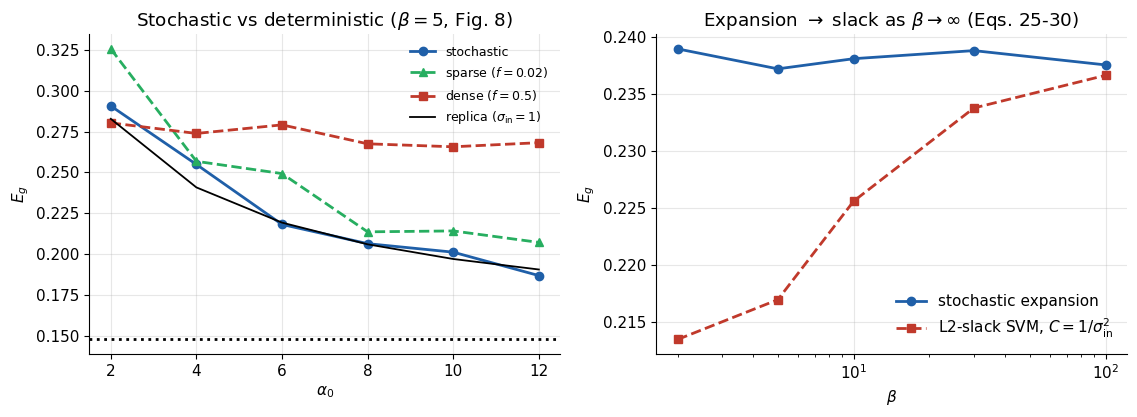

In [6]:
N0, beta, so = 70, 5.0, 0.5
a0s = np.array([2., 4., 6., 8., 10., 12.])
base = dict(N0=N0, teacher_a=1.0, sigma_out=so, learner=MaxMargin(), student="linear",
            measure_unpruned=False, n_test=0)

st = curve(a0s, "eg_pruned", 4, 0, 3, expansion=Stochastic(beta, 1.0), **base)
sp = curve(a0s, "eg_pruned", 4, 0, 4, expansion=Deterministic(beta, 0.02, 1.0), **base)
de = curve(a0s, "eg_pruned", 4, 0, 5, expansion=Deterministic(beta, 0.50, 1.0), **base)
thy = T.eg_curve_sigma_in_1(a0s, beta, so, pruned=True)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
ax[0].plot(a0s, st, "o-", color=ACCENT, label="stochastic")
ax[0].plot(a0s, sp, "^--", color=GREEN, label=r"sparse ($f=0.02$)")
ax[0].plot(a0s, de, "s--", color=TEACH, label=r"dense ($f=0.5$)")
ax[0].plot(a0s, thy, "k-", lw=1.3, label=r"replica ($\sigma_{\rm in}=1$)")
ax[0].axhline(min_generalization_error(so), ls=":", color="k")
ax[0].set(xlabel=r"$\alpha_0$", ylabel=r"$E_g$",
          title=fr"Stochastic vs deterministic ($\beta={beta:g}$, Fig. 8)")
ax[0].legend(fontsize=9, frameon=False)

# slack correspondence: on the same training sets, stochastic expansion vs L2-slack SVM
from experiments import slack_correspondence as S
cfg = S.Config(N0=50, alpha0=4.0, sigma_out=so, sigma_in=1.0,
               betas=[2.0, 5.0, 10.0, 30.0, 100.0], trials=8, seed=0)
res = S.run_check(cfg, n_jobs=-1)
ax[1].plot(res["betas"], res["eg_expanded"].mean(1), "o-", color=ACCENT, label="stochastic expansion")
ax[1].plot(res["betas"], res["eg_slack"].mean(1), "s--", color=TEACH,
           label=r"L2-slack SVM, $C=1/\sigma_{\rm in}^2$")
ax[1].set_xscale("log")
ax[1].set(xlabel=r"$\beta$", ylabel=r"$E_g$",
          title=r"Expansion $\to$ slack as $\beta\to\infty$ (Eqs. 25-30)")
ax[1].legend(frameon=False)
plt.tight_layout()
print("1 - cos(w_expanded, w_slack):", np.round(1 - res["cos"].mean(1), 4))

## 6. A quadratic teacher looks like label noise

The benefit is not special to label noise. Take a deterministic but **quadratic** teacher (Eq. 31, linear fraction $a$),

$$ y=\operatorname{sgn}\!\Big[a\,\tfrac1{\sqrt{N_0}}\mathbf w^0\!\cdot\!\mathbf x + (1-a)\,\tfrac1{N_0}\!\sum_{ij}W^0_{ij}x_ix_j\Big], $$

which a linear student cannot represent. Empirically its generalization matches a **noisy linear** teacher with effective label noise (Eq. 32)

$$ \sigma_{\rm out}=\frac{1-a}{a}. $$

Below, a stochastically expanded student learning the quadratic teacher (points) tracks the replica curve for a noisy linear teacher at the mapped $\sigma_{\rm out}$ (line) — the unrealizable complexity of the quadratic rule acts just like effective noise.

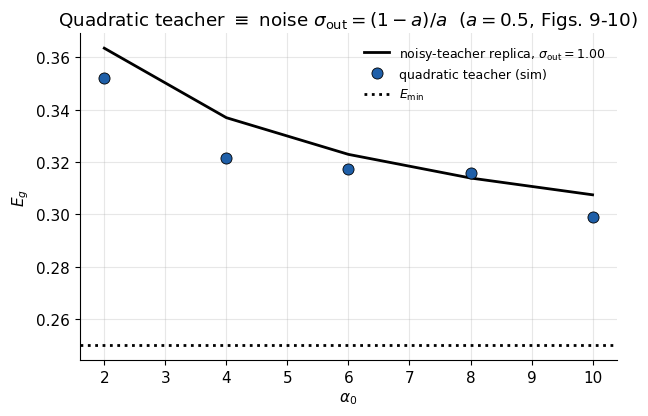

In [7]:
N0, beta, a = 70, 5.0, 0.5
sigma_eff = quad_to_noise_sigma(a)        # (1-a)/a
a0s = np.array([2., 4., 6., 8., 10.])

# quadratic teacher (sigma_out = 0); errors are Monte Carlo against fresh inputs
quad_sim = curve(a0s, "eg_pruned", 4, 0, 6, N0=N0, teacher_a=a, sigma_out=0.0,
                 expansion=Stochastic(beta, 1.0), learner=MaxMargin(), student="linear",
                 measure_unpruned=False, n_test=4000)

thy = T.eg_curve_sigma_in_1(a0s, beta, sigma_eff, pruned=True)
fig, ax = plt.subplots()
ax.plot(a0s, thy, "k-", label=fr"noisy-teacher replica, $\sigma_{{\rm out}}={sigma_eff:.2f}$")
ax.plot(a0s, quad_sim, "o", color=ACCENT, ms=8, mec="k", mew=0.6, label="quadratic teacher (sim)")
ax.axhline(min_generalization_error(sigma_eff), ls=":", color="k", label=r"$E_{\min}$")
ax.set(xlabel=r"$\alpha_0$", ylabel=r"$E_g$",
       title=fr"Quadratic teacher $\equiv$ noise $\sigma_{{\rm out}}=(1-a)/a$  ($a={a}$, Figs. 9-10)")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()

## 7. Beyond capacity: logistic regression

Max-margin is undefined above capacity, but the **logistic** loss (Eqs. 38-39) is not — gradient descent keeps improving the overlap as $\alpha_0$ grows past $\alpha_c$, approaching the optimal $\mathbf w=\mathbf w^0$. Below capacity the normalized weights converge to the max-margin direction (Soudry et al. 2018). The price: at fixed learning rate, expansion no longer helps — the **unexpanded** student attains the largest overlap in the explored regime (Fig. 14), since gradient descent already extracts useful information beyond capacity.

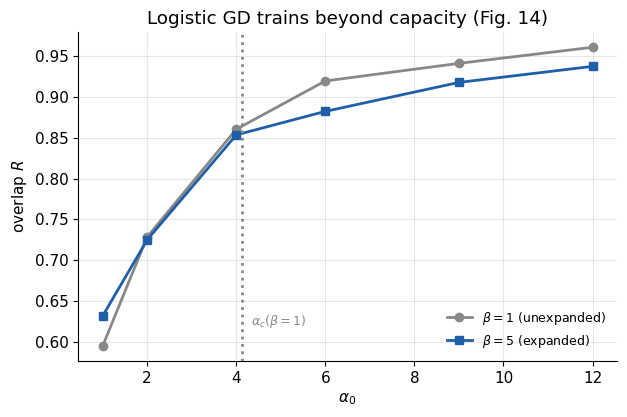

In [8]:
N0, so = 80, 0.5
a0s = np.array([1., 2., 4., 6., 9., 12.])

def R_curve(beta, series):
    expansion = NoExpansion() if beta == 1.0 else Stochastic(beta, 1.0)
    return curve(a0s, "R_pruned", 4, 0, series, N0=N0, teacher_a=1.0, sigma_out=so,
                 expansion=expansion, learner=Logistic(0.05, "paper", 2500, 0.0, 0.0, None), student="linear",
                 measure_unpruned=False, n_test=0)

fig, ax = plt.subplots()
ax.plot(a0s, R_curve(1.0, 7), "o-", color=GREY,   label=r"$\beta=1$ (unexpanded)")
ax.plot(a0s, R_curve(5.0, 8), "s-", color=ACCENT, label=r"$\beta=5$ (expanded)")
ax.axvline(T.capacity_alpha0(1.0, so), ls=":", color=GREY)
ax.text(T.capacity_alpha0(1.0, so) + 0.2, 0.62, r"$\alpha_c(\beta{=}1)$", color=GREY, fontsize=9)
ax.set(xlabel=r"$\alpha_0$", ylabel=r"overlap $R$",
       title=r"Logistic GD trains beyond capacity (Fig. 14)")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()

['fig02a', 'fig03a', 'fig04a', 'fig02b', 'fig03b', 'fig04b', 'fig05', 'fig06a', 'fig06c', 'fig06b', 'fig06d', 'fig07a', 'fig07b', 'fig08a', 'fig08b', 'fig09a', 'fig09b', 'fig10a', 'fig10b', 'fig11a', 'fig11b', 'fig12', 'fig13a_alpha0_3', 'fig13a_alpha0_8', 'fig13b_alpha0_3', 'fig13b_alpha0_8', 'fig14', 'slack']


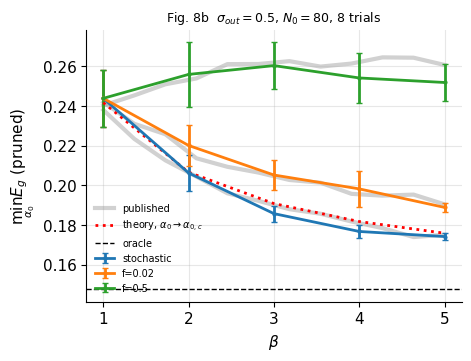

In [9]:
# Panels of the full figure runs; first run (from the repo root):
#   python -m experiments.reproduce all --profile quick --jobs 8
from experiments.notebook import list_panels, show

print(list_panels("quick"))
show("fig08b", "quick");

## Summary

* **Capacity** grows linearly with the expansion, $\alpha_c(\beta)=\beta\,\alpha_c(1)$, letting a wider student fit a larger training set.
* The extra capacity is used to absorb label noise, **improving generalization** of the underlying teacher-subspace weights.
* The gain is largest for **sparse** expansions and is realized by **pruning** the added units after learning — retaining uncorrelated activity only adds test noise ($R\ge m$).
* The mechanism is **slack regularization**: a wide expanded SVM equals a narrow slack SVM with trade-off $C=\sigma_{\rm in}^{-2}$.
* The replica mean-field theory ($\sigma_{\rm in}=1$) matches simulation throughout, and the same effective-noise picture covers complex (quadratic) teachers via $\sigma_{\rm out}=(1-a)/a$.

All curves above were produced from the `nn_expansion` package; see `tests/` for the validation suite and the `experiments/` scripts for the full-resolution drivers.